In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy.stats import spearmanr, pointbiserialr, chi2_contingency

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_seq_items', None)

In [3]:
# Load the dataset

df = pd.read_sas('LLCP2024.XPT')
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,PVTRESD1,COLGHOUS,STATERE1,CELPHON1,LADULT1,NUMADULT,RESPSLC1,LANDSEX3,SAFETIME,CTELNUM1,CELLFON5,CADULT1,CELLSEX3,PVTRESD3,CCLGHOUS,CSTATE1,LANDLINE,HHADULT,SEXVAR,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,PRIMINS2,PERSDOC3,MEDCOST1,CHECKUP1,EXERANY2,LASTDEN4,RMVTETH4,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNC1,CHCOCNC1,CHCCOPD3,ADDEPEV3,CHCKDNY2,HAVARTH4,DIABETE4,DIABAGE4,MARITAL,EDUCA,RENTHOM1,NUMHHOL4,NUMPHON4,CPDEMO1C,VETERAN3,EMPLOY1,CHILDREN,INCOME3,PREGNANT,WEIGHT2,HEIGHT3,DEAF,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,HADMAM,HOWLONG,CERVSCRN,CRVCLCNC,CRVCLPAP,CRVCLHPV,HADHYST2,HADSIGM4,COLNSIGM,COLNTES1,SIGMTES1,LASTSIG4,COLNCNCR,VIRCOLO1,VCLNTES2,SMALSTOL,STOLTEST,STOOLDN2,BLDSTFIT,SDNATES1,SMOKE100,SMOKDAY2,USENOW3,ECIGNOW3,LCSFIRST,LCSNUMCG,LCSCTSC1,LCSSCNCR,LCSCTWHN,ALCDAY4,AVEDRNK4,DRNK3GE5,MAXDRNKS,FLUSHOT7,FLSHTMY3,IMFVPLA5,PNEUVAC4,HIVTST7,HIVTSTD3,HIVRISK5,PDIABTS1,PREDIAB2,DIABTYPE,INSULIN1,CHKHEMO3,EYEEXAM1,DIABEYE1,DIABEDU1,FEETSORE,ARTHEXER,SHINGLE2,HPVADVC4,HPVADSH1,TETANUS1,CNCRDIFF,CNCRAGE,CNCRTYP2,CSRVTRT3,CSRVDOC1,CSRVSUM,CSRVRTRN,CSRVINST,CSRVINSR,CSRVDEIN,CSRVCLIN,CSRVPAIN,CSRVCTL2,PSATEST1,PSATIME1,PCPSARS2,PSASUGS1,PCSTALK2,CIMEMLO1,CDWORRY,CDDISCU1,CDHOUS1,CDSOCIA1,CAREGIV1,CRGVREL5,CRGVPRB4,CRGVALZD,CRGVNURS,CRGVPER2,CRGVHOU2,CRGVHRS2,CRGVLNG2,ACEDEPRS,ACEDRINK,ACEDRUGS,ACEPRISN,ACEDIVRC,ACEPUNCH,ACEHURT1,ACESWEAR,ACETOUCH,ACETTHEM,ACEHVSEX,ACEADSAF,ACEADNED,LSATISFY,EMTSUPRT,SDLONELY,SDHEMPLY,FOODSTMP,SDHFOOD1,SDHBILLS,SDHUTILS,SDHTRNSP,HOWSAFE1,MARIJAN1,MARJSMOK,MARJEAT,MARJVAPE,MARJDAB,MARJOTHR,USEMRJN4,LASTSMK2,STOPSMK2,MENTCIGS,MENTECIG,HEATTBCO,SSBSUGR2,SSBFRUT3,FIREARM5,GUNLOAD,LOADULK2,RCSGEND1,RCSXBRTH,RCSRLTN2,CASTHDX2,CASTHNO2,SOMALE,SOFEMALE,HADSEX,PFPPRVN4,TYPCNTR9,NOBCUSE8,QSTVER,QSTLANG,HPVDSHT,ICFQSTVR,_METSTAT,_URBSTAT,MSCODE,_STSTR,_STRWT,_RAWRAKE,_WT2RAKE,_IMPRACE,_CHISPNC,_CRACE1,CAGEG,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPWT2,_LLCPWT,_RFHLTH,_PHYS14D,_MENT14D,_HLTHPL2,_HCVU654,_TOTINDA,_EXTETH3,_ALTETH3,_DENVST3,_MICHD,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR2,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACEPRV,_SEX,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG1,_RFMAM23,_MAM402Y,_CRVSCRN,_RFPAP37,_HPV5YR1,_PAPHPV1,_HADCOLN,_CLNSCP2,_HADSIGM,_SGMSCP2,_SGMS102,_RFBLDS6,_STOLDN2,_VIRCOL2,_SBONTI2,_CRCREC3,_SMOKER3,_RFSMOK3,_CURECI3,LCSLAST_,LCSNUMC_,_LCSAGE,_LCSYSMK,_PACKDAY,_PACKYRS,_LCSYQTS,_LCSSMKG,_LCSELIG,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1.0,2.0,b'02282024',b'02',b'28',b'2024',1100.0,b'2024000001',2.024000e+09,1.0,1.0,NaN,1.0,2.0,1.0,1.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,3.0,2.0,88.0,88.0,3.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,1.0,2.0,2.0,2.0,2.0,1.0,3.0,NaN,3.0,4.0,1.0,2.0,NaN,1.0,2.0,7.0,88.0,99.0,NaN,131.0,504.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,3.0,NaN,NaN,1.0,1.0,7.0,1.0,7.0,2.0,NaN,NaN,2.0,NaN,3.0,1.0,NaN,NaN,1.0,7.0,NaN,888.0,NaN,NaN,NaN,1.0,777777.0,1.0,2.0,2.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,5.0,2.0,2.0,5.0,2.0,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,10.0,1.0,NaN,NaN,1.0,1.0,1.0,11011.0,28.393219,1.0,28.393219,1.0,NaN,NaN,NaN,NaN,1.0,0.465294,220.149005,261.525511,1.0,2.0,1.0,1.0,9.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,12.0,2.0,78.0,6.0,64.0,163.0,5942.0,2249.0,2.0,1.0,1.0,2.0,9.0,1.0,NaN,1.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0,1.0,NaN,NaN,2.0,NaN,NaN,NaN,NaN,6.0,2.0,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,2.0,2.0
1,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000002',2.024000e+09,1.

In [4]:
df.shape

(457670, 301)

In [5]:
# Drop the rows where the interview is partially completed (Include completed interview only)

df_filtered = df[df['DISPCODE'] == 1100.0]
df_filtered.shape

(372224, 301)

In [6]:
# Drop the rows where the diabetes types are unknown or unanswered. (Only include people who know which type of diabetes they have)

df_filtered = df_filtered[(df_filtered['DIABTYPE'] == 1) | (df_filtered['DIABTYPE'] == 2)]
df_filtered.shape

(10959, 301)

In [7]:
# Check null values 

nullColumns = df_filtered.columns[df_filtered.isna().any()]
len(nullColumns)

195

In [8]:
# Remove null values

df_filtered.drop(nullColumns, axis=1, inplace=True)
df_filtered.shape

(10959, 106)

In [9]:
# Remove irrelevant columns

df_filtered.drop(columns=['DISPCODE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'SEQNO', '_PSU',
                          '_SEX', '_AGE65YR', '_MRACE1', '_AGE_G', '_AGEG5YR', '_HISPANC', '_RACE', '_RACEG21', '_RACEPRV', 'CPDEMO1C', 'CHILDREN', 'DECIDE', 'DIFFALON', 'LCSCTSC1', 'HIVTST7', 'QSTVER', 'QSTLANG', '_STSTR', '_STRWT', '_RAWRAKE', '_WT2RAKE', '_DUALUSE', '_ASTHMS1',
                        '_LLCPWT2', '_LLCPWT', '_LTASTH1', '_CASTHM1', '_RACEGR3', '_EDUCAG', '_INCOMG1', '_SMOKER3', '_LCSAGE', 'DRNKANY6', '_AGE80', 'DIABETE4', '_HCVU654'], inplace=True)

df_filtered.shape

(10959, 62)

In [10]:
# Check duplicated values

df_filtered.duplicated().sum()

0

In [11]:
df_filtered.describe()

,_STATE,SEXVAR,GENHLTH,PHYSHLTH,MENTHLTH,PRIMINS2,PERSDOC3,CHECKUP1,EXERANY2,LASTDEN4,RMVTETH4,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,CHCSCNC1,ADDEPEV3,CHCKDNY2,HAVARTH4,DIABAGE4,MARITAL,EDUCA,RENTHOM1,EMPLOY1,INCOME3,WEIGHT2,HEIGHT3,DEAF,BLIND,DIFFWALK,DIFFDRES,SMOKE100,USENOW3,ECIGNOW3,ALCDAY4,FLUSHOT7,PNEUVAC4,HIVRISK5,DIABTYPE,INSULIN1,CHKHEMO3,EYEEXAM1,DIABEYE1,DIABEDU1,FEETSORE,_IMPRACE,_RFHLTH,_PHYS14D,_MENT14D,_HLTHPL2,_TOTINDA,_EXTETH3,_DENVST3,_RFBMI5,_CHLDCNT,_RFSMOK3,_CURECI3,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_AIDTST4
count,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,10959.000000,1.095900e+04,10959.000000,1.095900e+04,10959.000000,10959.000000
mean,34.879642,1.512182,3.291632,51.045807,61.197190,7.927457,1.554613,1.110047,1.398029,1.855005,3.799617,1.903276,1.931016,1.915503,1.817137,1.938589,1.773154,1.889315,1.488274,52.269915,2.199106,4.904280,1.331052,5.110685,19.571220,624.451136,700.410986,1.882927,1.916142,1.685464,1.925723,1.584086,2.968245,1.372570,641.690483,1.411443,1.556620,1.989598,1.903823,1.697144,10.132311,2.462633,3.211698,6.003832,1.919883,1.913222,1.421663,1.992974,1.648234,1.282416,1.402591,1.881194,1.480245,2.208322,1.249202,1.155489,1.061228,1.529045e+01,1.150926,1.260253e+03,1.113970,2.003924
std,16.670092,0.499874,0.993497,37.302365,36.530034,19.435493,0.718124,0.675712,0.590720,1.384627,3.072197,0.615214,0.754729,0.416154,0.497259,0.532368,0.575244,0.563113,0.651156,18.469777,1.567649,1.071397,0.740884,2.797163,30.665839,1935.670341,1240.683091,0.552648,0.487659,0.615015,0.330858,0.649474,0.341099,1.024067,337.790572,0.644363,1.174368,0.287352,0.294847,0.595645,23.321664,1.570293,2.272559,2.509552,0.390812,1.568433,0.601186,1.488057,1.236607,1.418367,0.639670,1.301554,1.071945,1.620316,0.790782,0.706593,0.554883,7.911869e+01,0.869909,1.048510e+04,0.851153,1.676873
min,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,55.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,101.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.397605e-79,1.000000,5.397605e-79,1.000000,1.000000
25%,24.000000,1.000000,3.000000,10.000000,20.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000,1.000000,40.000000,1.000000,4.000000,1.000000,1.000000,5.000000,165.000000,504.000000,2.000000,2.000000,1.000000,2.000000,1.000000,3.000000,1.000000,204.000000,1.000000,1.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,4.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,5.397605e-79,1.000000,5.397605e-79,1.000000,1.000000
50%,29.000000,2.000000,3.000000,30.000000,88.000000,3.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,50.000000,1.000000,5.000000,1.000000,7.000000,7.000000,198.000000,507.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,1.000000,888.000000,1

In [12]:
# We have mixture of continuous, categorical, ordinal, binary data. They need to be treated differently. 
# Some values are not real answers (missing/refused), so they need to be removed or imputed, but the encoding differs per column.
# The codebook value meanings for the 62 columns are loaded below to see which codes mean "refused", "don't know" or "not sure" in each column.

codebook = pd.read_excel('llcp2024_value_meanings_for_my_columns.xlsx')

for v in ["9", "7", "77", "99", "98", "999", "777"]:
    subset = codebook[codebook["value"].astype(str) == v][["variable", "meaning"]]
    if len(subset):
        print("\n==== value =", v, "====")
        print(subset.sort_values("variable").to_string(index=False))


==== value = 9 ====
variable                                                                                                              meaning
ADDEPEV3                                                                                                              Refused
 ASTHMA3                                                                                 Refused�Go to Section 06.06 CHCSCNC1
   BLIND                                                                                                              Refused
CHCKDNY2                                                                                                              Refused
CHCSCNC1                                                                                                              Refused
CHECKUP1                                                                                                              Refused
CVDCRHD4                                                                                         

In [13]:
# Change the meaning to lower case 
codebook["meaning"] = codebook["meaning"].str.lower()

# Identify Refused/Don't know/Not sure values per column
imputation_map = (
    codebook[codebook["meaning"].str.contains("refused|don't know|not sure", na=False)]
    .groupby("variable")["value"]
    .apply(lambda x: [int(v) for v in x if str(v).isdigit()])
    .to_dict()
)

print("Columns with Refused codes:")
for k, v in imputation_map.items():
    print(f"{k}: {v}")

# Build row-level mask: drop row if ANY column has its Refused value
mask = pd.Series(True, index=df_filtered.index)

for col, vals in imputation_map.items():
    if col in df_filtered.columns:
        mask &= ~df_filtered[col].isin(vals)

# Apply mask
df_clean = df_filtered.loc[mask].reset_index(drop=True)

print("Original rows:", len(df))
print("Rows after removing Refused/Don't know/Not sure:", len(df_clean))

Columns with Refused codes:
ADDEPEV3: [7, 9]
ALCDAY4: [777, 999]
ASTHMA3: [7, 9]
BLIND: [7, 9]
CHCKDNY2: [7, 9]
CHCSCNC1: [7, 9]
CHECKUP1: [7, 9]
CHKHEMO3: [77, 99]
CVDCRHD4: [7, 9]
CVDINFR4: [7, 9]
CVDSTRK3: [7, 9]
DEAF: [7, 9]
DIABAGE4: [98, 99]
DIABEDU1: [7, 9]
DIABEYE1: [7, 9]
DIABTYPE: [7, 9]
DIFFDRES: [7, 9]
DIFFWALK: [7, 9]
DROCDY4_: [900]
ECIGNOW3: [7, 9]
EDUCA: [9]
EMPLOY1: [9]
EXERANY2: [7, 9]
EYEEXAM1: [7, 9]
FEETSORE: [7, 9]
FLUSHOT7: [7, 9]
GENHLTH: [7, 9]
HAVARTH4: [7, 9]
HEIGHT3: [7777, 9999]
HIVRISK5: [7, 9]
INCOME3: [77, 99]
INSULIN1: [7, 9]
LASTDEN4: [7, 9]
MARITAL: [9]
MENTHLTH: [77, 99]
PERSDOC3: [7, 9]
PHYSHLTH: [77, 99]
PNEUVAC4: [7, 9]
PRIMINS2: [77, 99]
RENTHOM1: [7, 9]
RMVTETH4: [7, 9]
SMOKE100: [7, 9]
USENOW3: [7, 9]
WEIGHT2: [7777, 9999]
_AIDTST4: [9]
_CHLDCNT: [9]
_CURECI3: [9]
_DENVST3: [9]
_DRNKWK3: [99900]
_EXTETH3: [9]
_HCVU654: [9]
_HLTHPL2: [9]
_MENT14D: [9]
_PHYS14D: [9]
_RFBING6: [9]
_RFBMI5: [9]
_RFDRHV9: [9]
_RFHLTH: [9]
_RFSMOK3: [9]
_TOTINDA: [9]

In [14]:
# Recode survey-specific codes into real values (BRFSS codebook)

# WEIGHT2: 50-776 = pounds; 9023-9352 = 9000 + kilograms -> convert to pounds
w = df_clean["WEIGHT2"]
df_clean["WEIGHT2"] = np.where(w >= 9000, (w - 9000) * 2.20462, w)

# HEIGHT3: 200-711 = feet and inches (507 = 5 ft 7 in); 9061-9998 = 9000 + centimetres -> inches
h = df_clean["HEIGHT3"]
df_clean["HEIGHT3"] = np.where(h >= 9000, (h - 9000) / 2.54, (h // 100) * 12 + h % 100)

# 88 = "none" -> 0 days / 0 tests; CHKHEMO3 98 = never heard of the A1C test -> 0 tests
df_clean[["PHYSHLTH", "MENTHLTH"]] = df_clean[["PHYSHLTH", "MENTHLTH"]].replace(88, 0)
df_clean["CHKHEMO3"] = df_clean["CHKHEMO3"].replace({88: 0, 98: 0})

# 8 = "never": placed after the longest interval so each scale stays ordered
df_clean["LASTDEN4"] = df_clean["LASTDEN4"].replace(8, 5)
df_clean["EYEEXAM1"] = df_clean["EYEEXAM1"].replace(8, 5)
df_clean["DIABEDU1"] = df_clean["DIABEDU1"].replace(8, 7)

# DROCDY4_: SAS stores zero as a tiny float (e.g. 5.4e-79)
df_clean["DROCDY4_"] = df_clean["DROCDY4_"].round(6)

df_clean[["WEIGHT2", "HEIGHT3", "PHYSHLTH", "MENTHLTH", "CHKHEMO3", "LASTDEN4", "EYEEXAM1", "DIABEDU1", "DROCDY4_"]].describe().round(1)


,WEIGHT2,HEIGHT3,PHYSHLTH,MENTHLTH,CHKHEMO3,LASTDEN4,EYEEXAM1,DIABEDU1,DROCDY4_
count,5782.0,5782.0,5782.0,5782.0,5782.0,5782.0,5782.0,5782.0,5782.0
mean,202.9,67.0,7.2,4.5,3.0,1.7,2.2,5.4,9.4
std,51.0,4.2,10.8,8.7,4.9,1.1,1.0,2.2,21.4
min,85.0,41.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
25%,168.0,64.0,0.0,0.0,2.0,1.0,2.0,4.0,0.0
50%,198.0,67.0,1.0,0.0,2.0,1.0,2.0,7.0,0.0
75%,230.0,70.0,10.0,4.0,4.0,2.0,3.0,7.0,7.0
max,525.0,89.0,30.0,30.0,76.0,5.0,5.0,7.0,100.0


In [15]:
df_clean.isnull().sum()

_STATE      0
SEXVAR      0
GENHLTH     0
PHYSHLTH    0
MENTHLTH    0
PRIMINS2    0
PERSDOC3    0
CHECKUP1    0
EXERANY2    0
LASTDEN4    0
RMVTETH4    0
CVDINFR4    0
CVDCRHD4    0
CVDSTRK3    0
ASTHMA3     0
CHCSCNC1    0
ADDEPEV3    0
CHCKDNY2    0
HAVARTH4    0
DIABAGE4    0
MARITAL     0
EDUCA       0
RENTHOM1    0
EMPLOY1     0
INCOME3     0
WEIGHT2     0
HEIGHT3     0
DEAF        0
BLIND       0
DIFFWALK    0
DIFFDRES    0
SMOKE100    0
USENOW3     0
ECIGNOW3    0
ALCDAY4     0
FLUSHOT7    0
PNEUVAC4    0
HIVRISK5    0
DIABTYPE    0
INSULIN1    0
CHKHEMO3    0
EYEEXAM1    0
DIABEYE1    0
DIABEDU1    0
FEETSORE    0
_IMPRACE    0
_RFHLTH     0
_PHYS14D    0
_MENT14D    0
_HLTHPL2    0
_TOTINDA    0
_EXTETH3    0
_DENVST3    0
_RFBMI5     0
_CHLDCNT    0
_RFSMOK3    0
_CURECI3    0
DROCDY4_    0
_RFBING6    0
_DRNKWK3    0
_RFDRHV9    0
_AIDTST4    0
dtype: int64

In [16]:
df_clean.shape

(5782, 62)

In [17]:
# Check the proportion of target class

df_clean['DIABTYPE'].value_counts()

DIABTYPE
2.0    5246
1.0     536
Name: count, dtype: int64

In [18]:
# Convert the target value to interger type 

df_clean['DIABTYPE'] = df_clean['DIABTYPE'].astype(int)

df_clean['DIABTYPE'].value_counts()

DIABTYPE
2    5246
1     536
Name: count, dtype: int64

In [19]:
# Change the target value - type I to 0, type II to 1 for probability interpretaion and compatibility with metrics 

df_clean['DIABTYPE'] = df_clean['DIABTYPE'].replace({1: 0, 2: 1})

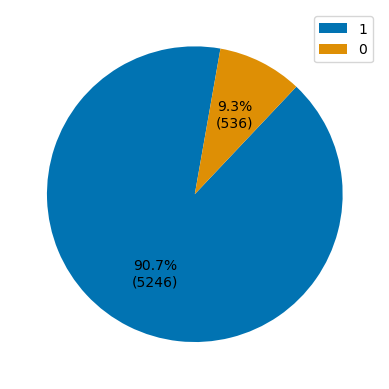

In [20]:
# Visualise the target value proportion
 
counts = df_clean['DIABTYPE'].value_counts()
values = counts.values 
labels = df_clean['DIABTYPE'].unique()

def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct*total/100))
        return '{p:.1f}%\n({v:d})'.format(p=pct, v=val)
    return my_autopct

colors = sns.color_palette('colorblind')
plt.pie(values, autopct=make_autopct(values), startangle=80, colors=colors)
plt.legend(labels)
plt.show()

In [21]:
# Categorise the columns by data type 

nominal = ['_STATE', 'MARITAL', 'EMPLOY1', 'RENTHOM1', '_IMPRACE', 'PRIMINS2', 'PERSDOC3', 'RMVTETH4', 'ECIGNOW3']

binary = ['SEXVAR','EXERANY2', 'CVDINFR4','CVDCRHD4','CVDSTRK3', 'ASTHMA3','CHCSCNC1','ADDEPEV3','CHCKDNY2','HAVARTH4',
          'DEAF','BLIND','DIFFWALK','DIFFDRES', 'FLUSHOT7', 'SMOKE100','PNEUVAC4','HIVRISK5','INSULIN1',
    'FEETSORE','_RFHLTH','_HLTHPL2', '_TOTINDA', '_EXTETH3','_DENVST3','_RFSMOK3','_CURECI3','_RFBING6','_RFDRHV9','_AIDTST4', '_RFBMI5']

ordinal = ['GENHLTH','CHECKUP1','LASTDEN4','EDUCA','INCOME3','_PHYS14D','_MENT14D','_CHLDCNT', 'DIABEYE1', 'DIABEDU1','EYEEXAM1', 'USENOW3']

continuous = ['PHYSHLTH','MENTHLTH','DIABAGE4','WEIGHT2','HEIGHT3','ALCDAY4','DROCDY4_','_DRNKWK3', 'CHKHEMO3']

In [22]:
# Categorise the columns by data type and check correlation based on the category 
# Spearmanr for continous-continous and ordinal-ordinal data types, Phi for binary-binary, Cramér’s V for nominal-nominal and nominal-binary, Point-biserial for continous-binary

def mixed_type_associations(
    df: pd.DataFrame,
    *,
    continuous=None,
    ordinal=None,
    binary=None,
    nominal=None,
    include_binary_continuous=True,
    include_nominal_binary=True,
    min_n=30,
    thresholds=None
):
    # Defaults
    continuous = [] if continuous is None else list(continuous)
    ordinal = [] if ordinal is None else list(ordinal)
    binary = [] if binary is None else list(binary)
    nominal = [] if nominal is None else list(nominal)

    if thresholds is None:
        thresholds = {"Spearman": 0.70, "Phi": 0.70, "CramersV": 0.70, "PointBiserial": 0.70}

    # Validate columns exist
    all_vars = set(continuous + ordinal + binary + nominal)
    missing = [c for c in all_vars if c not in df.columns]
    if missing:
        raise KeyError(f"These columns are missing from df: {missing}")

    def pairwise_dropna(a: pd.Series, b: pd.Series):
        tmp = pd.concat([a, b], axis=1).dropna()
        return tmp.iloc[:, 0], tmp.iloc[:, 1]

    def _enough_variation(x: pd.Series, y: pd.Series) -> bool:
        return x.nunique(dropna=True) >= 2 and y.nunique(dropna=True) >= 2

    def cramers_v(x: pd.Series, y: pd.Series) -> float:
        x, y = pairwise_dropna(x, y)
        if len(x) < min_n or not _enough_variation(x, y):
            return np.nan
        table = pd.crosstab(x, y)
        if table.shape[0] < 2 or table.shape[1] < 2:
            return np.nan
        chi2 = chi2_contingency(table)[0]
        n = table.to_numpy().sum()
        k = min(table.shape) - 1
        if k <= 0 or n <= 0:
            return np.nan
        return float(np.sqrt(chi2 / (n * k)))

    def phi_coeff(x: pd.Series, y: pd.Series) -> float:
        x, y = pairwise_dropna(x, y)
        if len(x) < min_n or not _enough_variation(x, y):
            return np.nan
        table = pd.crosstab(x, y)
        if table.shape[0] < 2 or table.shape[1] < 2:
            return np.nan
        chi2 = chi2_contingency(table)[0]
        n = table.to_numpy().sum()
        if n <= 0:
            return np.nan
        return float(np.sqrt(chi2 / n))

    def spearman_assoc(x: pd.Series, y: pd.Series) -> float:
        x, y = pairwise_dropna(x, y)
        if len(x) < min_n or not _enough_variation(x, y):
            return np.nan
        # Ensure numeric
        x = pd.to_numeric(x, errors="coerce")
        y = pd.to_numeric(y, errors="coerce")
        x, y = pairwise_dropna(x, y)
        if len(x) < min_n or not _enough_variation(x, y):
            return np.nan
        r, _ = spearmanr(x, y)
        return float(r)

    def point_biserial(x_bin: pd.Series, y_cont: pd.Series) -> float:
        x_bin, y_cont = pairwise_dropna(x_bin, y_cont)
        if len(x_bin) < min_n or not _enough_variation(x_bin, y_cont):
            return np.nan
        # Ensure numeric
        x_bin = pd.to_numeric(x_bin, errors="coerce")
        y_cont = pd.to_numeric(y_cont, errors="coerce")
        x_bin, y_cont = pairwise_dropna(x_bin, y_cont)
        if len(x_bin) < min_n:
            return np.nan
        # x must be binary 0/1-ish after cleaning
        if x_bin.nunique() != 2:
            return np.nan
        r, _ = pointbiserialr(x_bin, y_cont)
        return float(r)

    results = []

    def add_pair(v1, v2, method, value):
        results.append({"Var1": v1, "Var2": v2, "Method": method, "Association": value})

    # Continuous ↔ Continuous (Spearman)
    for i in range(len(continuous)):
        for j in range(i + 1, len(continuous)):
            v1, v2 = continuous[i], continuous[j]
            add_pair(v1, v2, "Spearman", spearman_assoc(df[v1], df[v2]))

    # Ordinal ↔ Ordinal (Spearman)
    for i in range(len(ordinal)):
        for j in range(i + 1, len(ordinal)):
            v1, v2 = ordinal[i], ordinal[j]
            add_pair(v1, v2, "Spearman", spearman_assoc(df[v1], df[v2]))

    # Binary ↔ Binary (Phi)
    for i in range(len(binary)):
        for j in range(i + 1, len(binary)):
            v1, v2 = binary[i], binary[j]
            add_pair(v1, v2, "Phi", phi_coeff(df[v1], df[v2]))

    # Nominal ↔ Nominal (Cramér’s V)
    for i in range(len(nominal)):
        for j in range(i + 1, len(nominal)):
            v1, v2 = nominal[i], nominal[j]
            add_pair(v1, v2, "CramersV", cramers_v(df[v1], df[v2]))

    # Binary ↔ Continuous (Point-biserial)
    if include_binary_continuous:
        for b in binary:
            for c in continuous:
                add_pair(b, c, "PointBiserial", point_biserial(df[b], df[c]))

    # Nominal ↔ Binary (Cramér’s V)
    if include_nominal_binary:
        for n in nominal:
            for b in binary:
                add_pair(n, b, "CramersV", cramers_v(df[n], df[b]))

    corr_df = pd.DataFrame(results)
    corr_df["abs_assoc"] = corr_df["Association"].abs()

    # Filter “strong” by method-specific thresholds
    def is_strong(row):
        thr = thresholds.get(row["Method"], None)
        return False if thr is None or pd.isna(row["Association"]) else (abs(row["Association"]) >= thr)

    strong_corr = corr_df[corr_df.apply(is_strong, axis=1)].sort_values("abs_assoc", ascending=False)

    return corr_df, strong_corr

In [23]:
# Compute correlations and show only the strong pairs
corr, strong_corr = mixed_type_associations(
    df_clean,
    continuous=[c for c in continuous if c in df_clean.columns],
    ordinal=[c for c in ordinal if c in df_clean.columns],
    binary=[c for c in binary if c in df_clean.columns],
    nominal=[c for c in nominal if c in df_clean.columns],
    include_binary_continuous=True,
    include_nominal_binary=True,
    min_n=30
)

if strong_corr.empty:
    print("No strong correlations found under current thresholds.")
else:
    display(
        strong_corr.sort_values("abs_assoc", ascending=False).reset_index(drop=True)
    )

,Var1,Var2,Method,Association,abs_assoc
0,PRIMINS2,_HLTHPL2,CramersV,1.000000,1.000000
1,RMVTETH4,_EXTETH3,CramersV,1.000000,1.000000
2,ECIGNOW3,_CURECI3,CramersV,1.000000,1.000000
3,EXERANY2,_TOTINDA,Phi,0.999622,0.999622
4,DROCDY4_,_DRNKWK3,Spearman,0.991432,0.991432
5,ALCDAY4,DROCDY4_,Spearman,-0.913460,0.913460
6,ALCDAY4,_DRNKWK3,Spearman,-0.909101,0.909101
7,_RFDRHV9,_DRNKWK3,PointBiserial,0.723953,0.723953
8,DIABEYE1,EYEEXAM1,Spearman,0.705247,0.705247


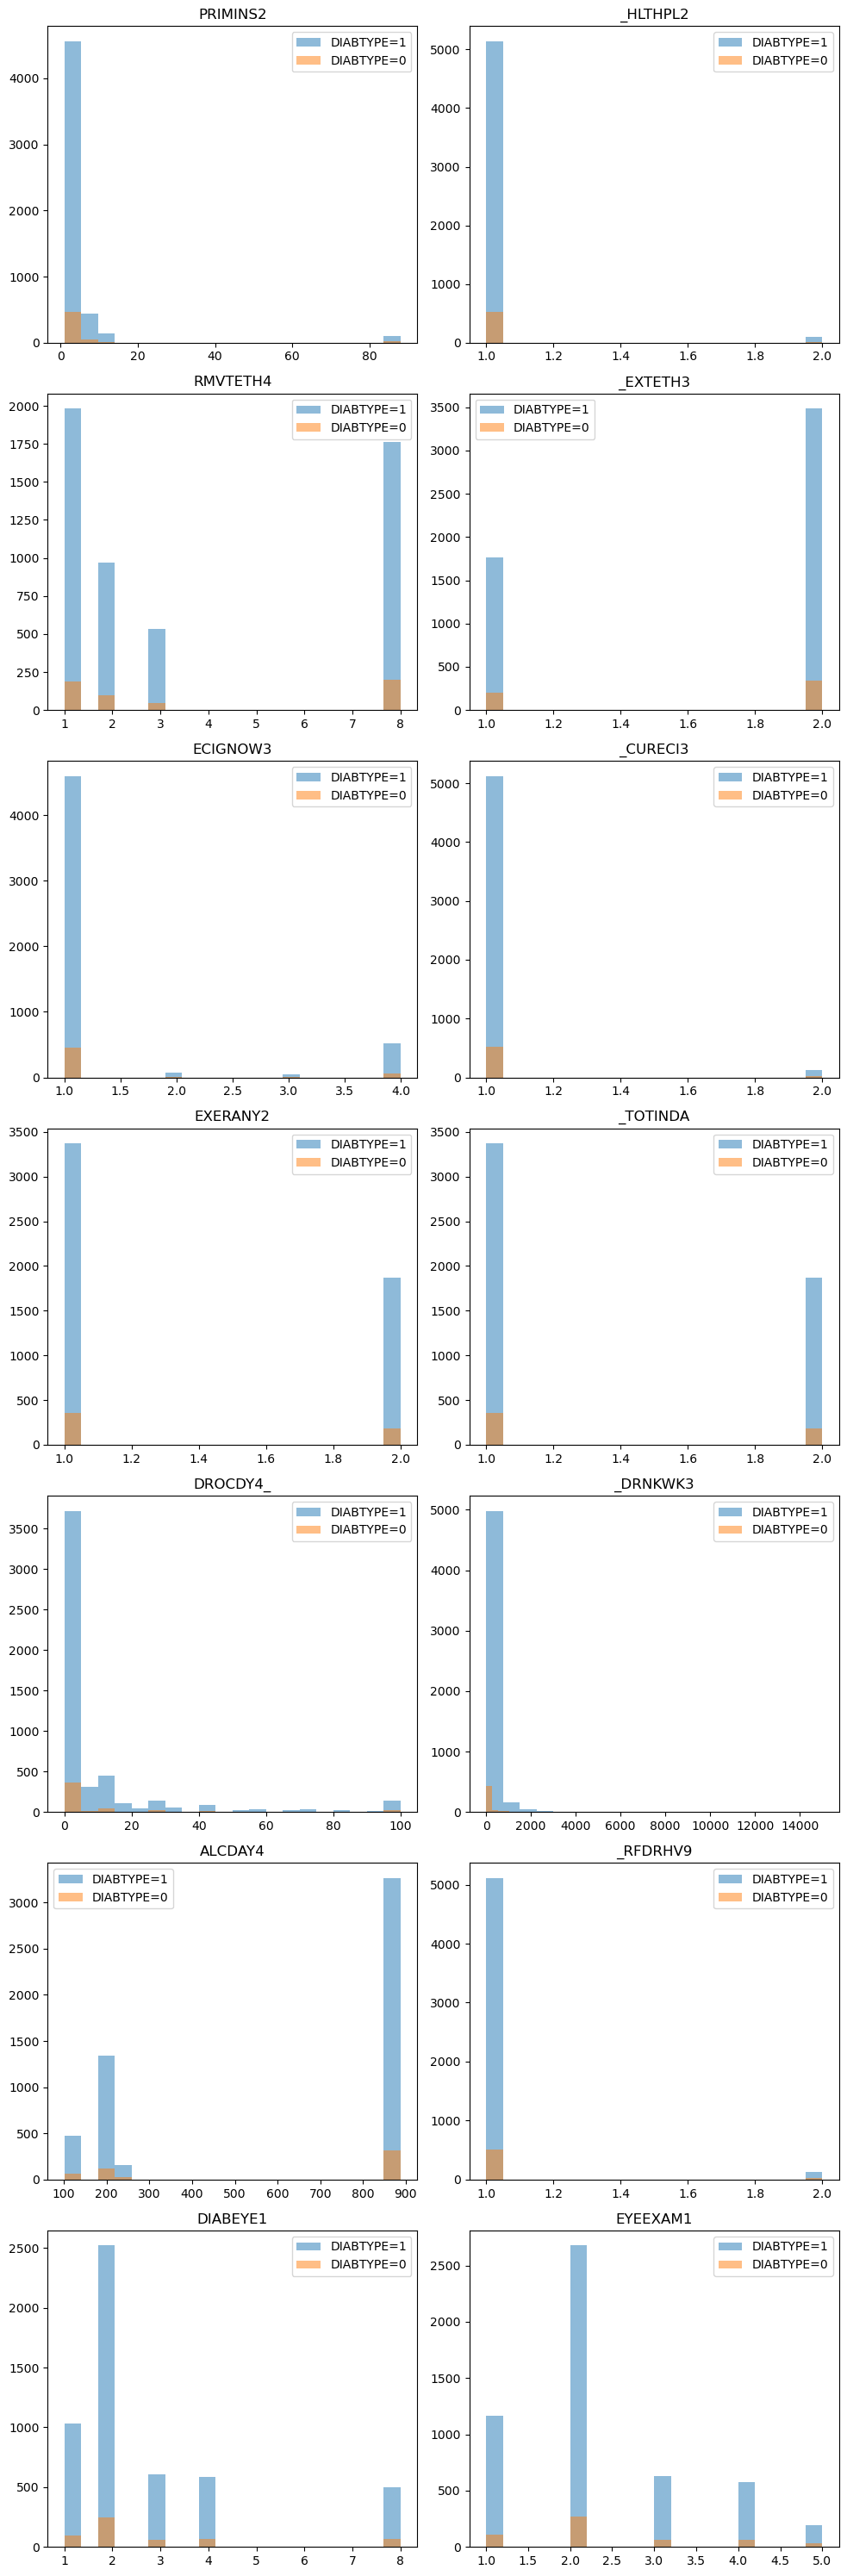

In [24]:
# Distribution of the correlated candidate features by diabetes type

features = [
    'PRIMINS2', '_HLTHPL2', 'RMVTETH4','_EXTETH3','ECIGNOW3','_CURECI3',
    'EXERANY2','_TOTINDA','DROCDY4_','_DRNKWK3', 'ALCDAY4', '_RFDRHV9', 'DIABEYE1', 'EYEEXAM1'
]

diab_types = df_clean['DIABTYPE'].unique()

plt.figure(figsize=(10, 30))

for i, col in enumerate(features, 1):
    plt.subplot(7, 2, i)
    
    for d in diab_types:
        subset = df_clean[df_clean['DIABTYPE'] == d]
        plt.hist(
            subset[col],
            bins=20,
            alpha=0.5,
            label=f'DIABTYPE={d}'
        )
    
    plt.title(col)
    plt.legend()

plt.tight_layout()
plt.show()

In [25]:
# Drop one of the highly correlated pairs

df_clean.drop(columns=['_EXTETH3', '_CURECI3', '_HLTHPL2', '_TOTINDA', '_DRNKWK3', 'ALCDAY4', 'DIABEYE1'], inplace=True)
df_clean.shape

(5782, 55)

In [26]:
# drop unstable variables (sign_consistency less than 0.8) from stability test below. 

df_clean.drop(columns=['SMOKE100', 'RMVTETH4', 'RENTHOM1', 'CVDCRHD4', 'EMPLOY1', 'CHECKUP1', '_STATE', 
                       '_IMPRACE', 'PRIMINS2', 'CVDINFR4', 'RMVTETH4', 'ECIGNOW3'], inplace=True)

In [27]:
df_clean.shape

(5782, 44)

In [28]:
df_clean.columns

Index(['SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'PERSDOC3', 'EXERANY2',
       'LASTDEN4', 'CVDSTRK3', 'ASTHMA3', 'CHCSCNC1', 'ADDEPEV3', 'CHCKDNY2',
       'HAVARTH4', 'DIABAGE4', 'MARITAL', 'EDUCA', 'INCOME3', 'WEIGHT2',
       'HEIGHT3', 'DEAF', 'BLIND', 'DIFFWALK', 'DIFFDRES', 'USENOW3',
       'FLUSHOT7', 'PNEUVAC4', 'HIVRISK5', 'DIABTYPE', 'INSULIN1', 'CHKHEMO3',
       'EYEEXAM1', 'DIABEDU1', 'FEETSORE', '_RFHLTH', '_PHYS14D', '_MENT14D',
       '_DENVST3', '_RFBMI5', '_CHLDCNT', '_RFSMOK3', 'DROCDY4_', '_RFBING6',
       '_RFDRHV9', '_AIDTST4'],
      dtype='object')

In [29]:
# Column meanings

feature_dict={
'SEXVAR': 'Sex', 
'_DENVST3': 'Have you visited a dentist, dental hygenist or dental clinic in the past year',
'GENHLTH': 'Evaluation on your general health', 
'PERSDOC3': 'Do you have personal health care provider?',
'LASTDEN4': 'How long has it been since you last visited a dentist or a dental clinic for any reason?',
'CVDSTRK3': '(Ever told) (you had) a stroke.',
'ASTHMA3': '(Ever told) (you had) asthma?',    
'CHCSCNC1': '(Ever told) (you had) skin cancer that is not melanoma?',
'CHCOCNC1': '(Ever told) (you had) melanoma or any other types of cancer?',
'CHCCOPD3': '(Ever told) (you had) C.O.P.D. (chronic obstructive pulmonary disease), emphysema or chronic bronchitis?',
'ADDEPEV3': '(Ever told) (you had) a depressive disorder (including depression, major depression, dysthymia, or minor depression)?',
'CHCKDNY2': 'Not including kidney stones, bladder infection or incontinence, were you ever told you had kidney disease?',
'HAVARTH4': '(Ever told) (you had) some form of arthritis, rheumatoid arthritis, gout, lupus, or fibromyalgia?',
'DIABETE4': 'Ever told (you had) diabetes?',
'MARITAL': 'Are you: (marital status)',
'EDUCA': 'What is the highest grade or year of school you completed?',
'INCOME3': 'Annual household income from all sources',
'WEIGHT2': 'About how much do you weigh without shoes?',
'HEIGHT3': 'About how tall are you without shoes?',
'DEAF': 'Are you deaf or do you have serious difficulty hearing?',
'BLIND': 'Are you blind or do you have serious difficulty seeing, even when wearing glasses?',
'DIFFWALK': 'Do you have serious difficulty walking or climbing stairs?',
'DIFFDRES': 'Do you have difficulty dressing or bathing?',
'FLUSHOT7': 'Have you had a flu vaccine in the past year?',
'INSULIN1': 'Are you now taking insulin?',
'EYEEXAM1': 'When was the last time you had an eye exam in which the pupils were dilated, making you temporarily sensitive to bright light?',
'FEETSORE': 'Have you ever had any sores or irritations on your feet that took more than four weeks to heal?',
'DIABEYE1': 'When was the last time you were taken a photo of the back of your eye with a specialized camera?',
'_RFDRHV9': 'Are you a heavy drinker?',
'DROCDY4_': 'Drink-occasions per day',
'_PHYS14D': '3 level not good physical health status: 0 days, 1-13 days, 14-30 days',
'_RFBING6': 'Are you a binge drinker?',
'MENTHLTH': 'For how many days during the past 30 days was your mental health not good?',
'_RFHLTH': 'Are you in good or better health?',
'PNEUVAC4': 'Have you ever had a pneumonia shot?',
'DIABAGE4': 'How old were you when you were first told you had diabetes?',
'HIVRISK5': 'You have injected any drug other than those prescribed for you OR have been treated for a sexually transmitted disease or STD OR have given or received money or drugs in exchange for sex in the past year',
'DIABTYPE': 'Diabetes type',
'CHKHEMO3': 'About how many times in the past 12 months has a doctor, nurse, or other health professional checked you for A-one-C?',
'DIABEDU1': 'When was the last time you took a course or class in how to manage your diabetes yourself?',
'_RFBMI5': 'Are you overweight or obese? (bmi > 25)',
'_CHLDCNT': 'Number of children in household',
'_RFSMOK3': 'Are you currently smoking?',
'_AIDTST4': 'Have you ever been tested for HIV?'
}

In [30]:
# Drop more duplicated columns after checking the meaning of columns per category 

df_clean.drop(columns=['HIVRISK5', '_MENT14D', '_RFHLTH', '_PHYS14D', 'PHYSHLTH'], inplace=True)
df_clean.shape

(5782, 39)

In [31]:
# Check the correlation again

corr, strong_corr = mixed_type_associations(
    df_clean,
    continuous=[c for c in continuous if c in df_clean.columns],
    ordinal=[c for c in ordinal if c in df_clean.columns],
    binary=[c for c in binary if c in df_clean.columns],
    nominal=[c for c in nominal if c in df_clean.columns],
    include_binary_continuous=True,
    include_nominal_binary=True,
    min_n=30
)

In [32]:
if strong_corr.empty:
    print("No strong correlations found.")
else:
    display(
        strong_corr
        .sort_values("abs_assoc", ascending=False)
        .reset_index(drop=True)
    )

No strong correlations found.


In [33]:
# Checking the relationship strengths

top_pairs = corr.sort_values("abs_assoc", ascending=False).head(3)

In [34]:
# Association over 0.45 (Moderate association)

display(top_pairs)

,Var1,Var2,Method,Association,abs_assoc
278,SEXVAR,HEIGHT3,PointBiserial,-0.692322,0.692322
393,_RFDRHV9,DROCDY4_,PointBiserial,0.535446,0.535446
403,_RFBMI5,WEIGHT2,PointBiserial,0.483555,0.483555


Meaning of features in high correlation 

* _RFDRHV9: Heavy drinkers (adult men having more than 14 drinks per week and adult women having more than 7 drinks per week)

* DROCDY4_: Drink-occasions-per-day

* _RFBING6: Binge drinkers (males having five or more drinks on one occasion, females having four or more drinks on one occasion)

* WEIGHT2: About how much do you weigh without shoes?

* HEIGHT3: About how tall are you without shoes?   

In [35]:
# Seperate features and target as X and y 

X = df_clean.drop('DIABTYPE', axis=1)
y = df_clean['DIABTYPE']

X.shape, y.shape

((5782, 38), (5782,))

In [36]:
# Train-Test set split 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((4625, 38), (4625,), (1157, 38), (1157,))

In [37]:
y.value_counts()

DIABTYPE
1    5246
0     536
Name: count, dtype: int64

In [38]:
X_train.columns

Index(['SEXVAR', 'GENHLTH', 'MENTHLTH', 'PERSDOC3', 'EXERANY2', 'LASTDEN4',
       'CVDSTRK3', 'ASTHMA3', 'CHCSCNC1', 'ADDEPEV3', 'CHCKDNY2', 'HAVARTH4',
       'DIABAGE4', 'MARITAL', 'EDUCA', 'INCOME3', 'WEIGHT2', 'HEIGHT3', 'DEAF',
       'BLIND', 'DIFFWALK', 'DIFFDRES', 'USENOW3', 'FLUSHOT7', 'PNEUVAC4',
       'INSULIN1', 'CHKHEMO3', 'EYEEXAM1', 'DIABEDU1', 'FEETSORE', '_DENVST3',
       '_RFBMI5', '_CHLDCNT', '_RFSMOK3', 'DROCDY4_', '_RFBING6', '_RFDRHV9',
       '_AIDTST4'],
      dtype='object')

In [39]:
# Updated features by category 

nominal = ['MARITAL', 'PERSDOC3']

binary = ['SEXVAR','EXERANY2', 'CVDSTRK3', 'ASTHMA3','CHCSCNC1','ADDEPEV3','CHCKDNY2','HAVARTH4',
          'DEAF','BLIND','DIFFWALK','DIFFDRES', 'FLUSHOT7', 'PNEUVAC4', 'INSULIN1',
    'FEETSORE', '_DENVST3','_RFSMOK3','_RFBING6','_RFDRHV9','_AIDTST4', '_RFBMI5']

ordinal = ['GENHLTH','LASTDEN4','EDUCA','INCOME3','_CHLDCNT','DIABEDU1','EYEEXAM1','USENOW3']

continuous = ['MENTHLTH','DIABAGE4','WEIGHT2','HEIGHT3','DROCDY4_', 'CHKHEMO3']


In [40]:
# Logistic regression (class-balanced) with 10-fold CV performance

class ClipValues(BaseEstimator, TransformerMixin):
    """Clips extreme numeric values to reduce numerical instability."""
    def __init__(self, lo=-50.0, hi=50.0):
        self.lo = lo
        self.hi = hi

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lo, self.hi)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object) if input_features is not None else None

    def __sklearn_is_fitted__(self):
        # Stateless transformer: always "fitted" (stops Pipeline's not-fitted FutureWarning)
        return True

def safe_exp(x, clip=20.0):
    """Exponentiate safely: exp(+-20) is large enough for OR interpretation without overflow."""
    x = np.asarray(x, dtype=float)
    return np.exp(np.clip(x, -clip, clip))

# -----------------------------
# 1) Preprocessing by type
# -----------------------------
nominal_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])

binary_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=True)),
])

ordinal_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler(with_mean=True, with_std=True)),
    ("clip", ClipValues(lo=-10.0, hi=10.0)),
])

continuous_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=True, with_std=True)),
    ("clip", ClipValues(lo=-10.0, hi=10.0)),
])

prep = ColumnTransformer(
    transformers=[
        ("nom", nominal_tf, nominal),
        ("bin", binary_tf, binary),
        ("ord", ordinal_tf, ordinal),
        ("con", continuous_tf, continuous),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

# -----------------------------
# 2) Model (class-balanced)
# -----------------------------
model = Pipeline(steps=[
    ("prep", prep),
    ("clf", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        solver="lbfgs",
        penalty="l2",
    )),
])

# -----------------------------
# 3) 10-fold CV metrics (TRAIN only)
# -----------------------------
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scoring = {
    "balanced_acc": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False,
    error_score="raise",
)

cv_summary = pd.DataFrame({
    m: [np.mean(cv_results[f"test_{m}"]), np.std(cv_results[f"test_{m}"])]
    for m in scoring.keys()
}, index=["mean", "std"]).T

print("\n10-fold CV performance on TRAIN (mean ± std):")
print(cv_summary)

# -----------------------------
# 4) Fit on full TRAIN, evaluate on TEST
# -----------------------------
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

print("\nHeld-out TEST metrics:")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"F1-macro:         {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC-AUC:          {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC (AP):      {average_precision_score(y_test, y_proba):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# -----------------------------
# 5) Coef + feature names (from fitted model)
# -----------------------------
feature_names_full = model.named_steps["prep"].get_feature_names_out()
coef_full = model.named_steps["clf"].coef_[0]

impact_df = pd.DataFrame({
    "feature": feature_names_full,
    "coef": coef_full,
})
impact_df["odds_ratio_class1_vs_0"] = safe_exp(impact_df["coef"].to_numpy(), clip=20.0)
impact_df["odds_ratio_class0_vs_1"] = safe_exp(-impact_df["coef"].to_numpy(), clip=20.0)
impact_df["abs_coef"] = impact_df["coef"].abs()
impact_df["favors_class"] = np.where(impact_df["coef"] > 0, "Class 1", "Class 0")

# -----------------------------
# 6) Build coef_mat across folds (ALIGNED by feature names)
# -----------------------------
feature_ref = feature_names_full
coef_list = []

for tr_idx, _ in cv.split(X_train, y_train):
    X_tr = X_train.iloc[tr_idx]
    y_tr = np.asarray(y_train)[tr_idx]

    m = clone(model)
    m.fit(X_tr, y_tr)

    fn = m.named_steps["prep"].get_feature_names_out()
    cb = m.named_steps["clf"].coef_[0]

    cb_aligned = (
        pd.Series(cb, index=fn)
        .reindex(feature_ref)
        .fillna(0.0)
        .to_numpy()
    )
    coef_list.append(cb_aligned)

coef_mat = np.vstack(coef_list)

# -----------------------------
# 7) CV-based 95% percentile CIs + fold stability
# -----------------------------
ci_lower = np.percentile(coef_mat, 2.5, axis=0)
ci_upper = np.percentile(coef_mat, 97.5, axis=0)

impact_df["coef_ci_lower_95"] = ci_lower
impact_df["coef_ci_upper_95"] = ci_upper

impact_df["or1_ci_lower_95"] = safe_exp(ci_lower, clip=20.0)
impact_df["or1_ci_upper_95"] = safe_exp(ci_upper, clip=20.0)

impact_df["or0_ci_lower_95"] = safe_exp(-ci_upper, clip=20.0)
impact_df["or0_ci_upper_95"] = safe_exp(-ci_lower, clip=20.0)

impact_df["ci_excludes_0"] = ~(
    (impact_df["coef_ci_lower_95"] <= 0) & (impact_df["coef_ci_upper_95"] >= 0)
)

mean_coef_cv = coef_mat.mean(axis=0)
std_coef_cv  = coef_mat.std(axis=0)

mean_sign = np.sign(mean_coef_cv)
fold_sign = np.sign(coef_mat)

consistent = (fold_sign == mean_sign).astype(float)
consistent[:, mean_sign == 0] = 0.0

impact_df["coef_mean_cv"] = mean_coef_cv
impact_df["coef_std_cv"] = std_coef_cv
impact_df["sign_consistency_10fold"] = consistent.mean(axis=0)

# -----------------------------
# 8) Sort 
# -----------------------------
impact_df = impact_df.sort_values(
    ["sign_consistency_10fold", "abs_coef"],
    ascending=[False, False]
).reset_index(drop=True)


10-fold CV performance on TRAIN (mean ± std):
                  mean       std
balanced_acc  0.653535  0.025584
f1_macro      0.537252  0.013362
roc_auc       0.718046  0.044122
pr_auc        0.953716  0.009084



Held-out TEST metrics:
Balanced accuracy: 0.6530
F1-macro:         0.5426
ROC-AUC:          0.7089
PR-AUC (AP):      0.9503

Confusion Matrix:
 [[ 63  44]
 [297 753]]

Classification Report:
               precision    recall  f1-score   support

           0       0.17      0.59      0.27       107
           1       0.94      0.72      0.82      1050

    accuracy                           0.71      1157
   macro avg       0.56      0.65      0.54      1157
weighted avg       0.87      0.71      0.76      1157



In [41]:
important = impact_df[
    (impact_df["abs_coef"] >= 0.3) & (impact_df["sign_consistency_10fold"] >= 0.8) &
    ((impact_df["odds_ratio_class1_vs_0"] >= 1.25) | (impact_df["odds_ratio_class1_vs_0"] <= 0.75))
].copy()

important.sort_values(['odds_ratio_class1_vs_0'], ascending=False)

,feature,coef,odds_ratio_class1_vs_0,odds_ratio_class0_vs_1,abs_coef,favors_class,coef_ci_lower_95,coef_ci_upper_95,or1_ci_lower_95,or1_ci_upper_95,or0_ci_lower_95,or0_ci_upper_95,ci_excludes_0,coef_mean_cv,coef_std_cv,sign_consistency_10fold
0,bin__INSULIN1_2.0,0.907259,2.477523,0.403629,0.907259,Class 1,0.858426,0.949333,2.359444,2.583985,0.386999,0.423829,True,0.911622,0.030496,1.0
2,nom__MARITAL_4.0,0.567762,1.764314,0.566793,0.567762,Class 1,0.484580,0.695229,1.623493,2.004167,0.498960,0.615956,True,0.563427,0.070515,1.0
4,nom__PERSDOC3_3.0,0.443764,1.558563,0.641617,0.443764,Class 1,0.272453,0.598326,1.313182,1.819071,0.549731,0.761509,True,0.455706,0.099054,1.0
5,con__DIABAGE4,0.413915,1.512728,0.661057,0.413915,Class 1,0.376599,0.466468,1.457320,1.594353,0.627214,0.686191,True,0.415819,0.026148,1.0
6,con__WEIGHT2,0.349882,1.418900,0.704771,0.349882,Class 1,0.298533,0.423046,1.347879,1.526605,0.655048,0.741906,True,0.352585,0.042190,1.0
7,ord__INCOME3,0.311217,1.365085,0.732555,0.311217,Class 1,0.246885,0.374381,1.280032,1.454091,0.687715,0.781231,True,0.313401,0.040943,1.0
3,bin__CHCKDNY2_2.0,-0.516001,0.596903,1.675314,0.516001,Class 0,-0.569691,-0.451493,0.565700,0.636677,1.570655,1.767721,True,-0.514912,0.047027,1.0
1,bin___DENVST3_2.0,-0.643733,0.525328,1.903573,0.643733,Class 0,-0.715057,-0.513517,0.489164,0.598388,1.671158,2.044304,True,-0.636928,0.062002,1.0


In [42]:
important.feature.nunique()

8

In [43]:
# Rename the columns

dictionary = {
    "bin__INSULIN1_2.0": "Currently not taking insulin",
    "bin___RFBMI5_2.0": "Overweight or obese (BMI > 25)",
    "bin__CHCKDNY2_2.0": "Not told to have kidney disease",
    "bin___DENVST3_2.0": "Haven't visited a dentist in the past year",
    "nom__PERSDOC3_3.0": "No personal health care provider",
    "nom__PERSDOC3_1.0": "One personal health care provider",
    "nom__PERSDOC3_2.0": "More than one personal health care provider",
    "nom__MARITAL_4.0": "Marital status: Separated",
    "con__DIABAGE4": "Age first told to have diabetes",
    "bin___RFHLTH_2.0": "Fair or poor health",
    "bin__ADDEPEV3_2.0": "No depressive disorder diagnosis",
    "bin___RFDRHV9_2.0": "Heavy drinker (WHO definition)",
    "bin___RFSMOK3_2.0": "Current smoker",
    "bin__CHCSCNC1_2.0": "No skin cancer diagnosis",
    "bin__USENOW3_1.0": "Use smokeless tobacco everyday",
    "con__WEIGHT2": "Weight",
    "ord__INCOME3": "Household income"
}

important["feature"] = important["feature"].map(dictionary).fillna(important["feature"])

In [44]:
important['feature']

0                  Currently not taking insulin
1    Haven't visited a dentist in the past year
2                     Marital status: Separated
3               Not told to have kidney disease
4              No personal health care provider
5               Age first told to have diabetes
6                                        Weight
7                              Household income
Name: feature, dtype: object

In [45]:
# Separte strong predictors for Type I and Type II each
Type1 = important[important['coef'] < 0]
Type2 = important[important['coef'] > 0]

In [46]:
Type1.sort_values(['odds_ratio_class0_vs_1'], ascending=False)

,feature,coef,odds_ratio_class1_vs_0,odds_ratio_class0_vs_1,abs_coef,favors_class,coef_ci_lower_95,coef_ci_upper_95,or1_ci_lower_95,or1_ci_upper_95,or0_ci_lower_95,or0_ci_upper_95,ci_excludes_0,coef_mean_cv,coef_std_cv,sign_consistency_10fold
1,Haven't visited a dentist in the past year,-0.643733,0.525328,1.903573,0.643733,Class 0,-0.715057,-0.513517,0.489164,0.598388,1.671158,2.044304,True,-0.636928,0.062002,1.0
3,Not told to have kidney disease,-0.516001,0.596903,1.675314,0.516001,Class 0,-0.569691,-0.451493,0.565700,0.636677,1.570655,1.767721,True,-0.514912,0.047027,1.0


In [47]:
Type2.sort_values(['odds_ratio_class1_vs_0'], ascending=False)

,feature,coef,odds_ratio_class1_vs_0,odds_ratio_class0_vs_1,abs_coef,favors_class,coef_ci_lower_95,coef_ci_upper_95,or1_ci_lower_95,or1_ci_upper_95,or0_ci_lower_95,or0_ci_upper_95,ci_excludes_0,coef_mean_cv,coef_std_cv,sign_consistency_10fold
0,Currently not taking insulin,0.907259,2.477523,0.403629,0.907259,Class 1,0.858426,0.949333,2.359444,2.583985,0.386999,0.423829,True,0.911622,0.030496,1.0
2,Marital status: Separated,0.567762,1.764314,0.566793,0.567762,Class 1,0.484580,0.695229,1.623493,2.004167,0.498960,0.615956,True,0.563427,0.070515,1.0
4,No personal health care provider,0.443764,1.558563,0.641617,0.443764,Class 1,0.272453,0.598326,1.313182,1.819071,0.549731,0.761509,True,0.455706,0.099054,1.0
5,Age first told to have diabetes,0.413915,1.512728,0.661057,0.413915,Class 1,0.376599,0.466468,1.457320,1.594353,0.627214,0.686191,True,0.415819,0.026148,1.0
6,Weight,0.349882,1.418900,0.704771,0.349882,Class 1,0.298533,0.423046,1.347879,1.526605,0.655048,0.741906,True,0.352585,0.042190,1.0
7,Household income,0.311217,1.365085,0.732555,0.311217,Class 1,0.246885,0.374381,1.280032,1.454091,0.687715,0.781231,True,0.313401,0.040943,1.0


In [48]:
Type1.shape, Type2.shape

((2, 16), (6, 16))

In [49]:
# Create Radar Chart showing the impact on Type 1 and Type 2 Diabetes visually 
# Based on the Plotly radar chart example: https://plotly.com/python/radar-chart/

fig = go.Figure()

fig.add_trace(go.Scatterpolar(
      r = Type1['odds_ratio_class0_vs_1'],
      theta = Type1['feature'],
      fill = 'toself',
      name = 'Type 1'
))

fig.add_trace(go.Scatterpolar(
      r = Type2['odds_ratio_class1_vs_0'],
      theta = Type2['feature'],
      fill='toself',
      name='Type 2'
))

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(
            size=18
        )
    ),
    width=900,
    height=500,
    margin=dict(l=80, r=80, t=60, b=60),
    polar=dict(
        domain=dict(x=[0.15, 0.85], y=[0.1, 0.9]),
        radialaxis=dict(
            visible=True,
            range=[1, 3]
        ),
        angularaxis=dict(
            tickfont=dict(
                size=12
            )
        )
    ),
    showlegend=True
)

fig.show()

In [50]:
# Type 1 radar chart

fig = px.line_polar(
    Type1,
    r='odds_ratio_class0_vs_1',
    theta='feature',
    line_close=True
)

fig.update_traces(
    fill='toself',
    name='Type 1 Diabetes',
    showlegend=True
)

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=15)
    ),
    width=900,
    height=500,
    margin=dict(l=80, r=80, t=80, b=60),
    polar=dict(
        domain=dict(x=[0.15, 0.85], y=[0.1, 0.9]),
        radialaxis=dict(
            visible=True,
            range=[1, 2]
        ),
        angularaxis=dict(
            tickfont=dict(size=12)
        )
    ),
    showlegend=True  
)

fig.show()

In [51]:
df_clean.groupby('DIABTYPE')[ '_CHLDCNT'].value_counts()

DIABTYPE  _CHLDCNT
0         1.0          438
          2.0           45
          3.0           31
          4.0           12
          5.0            5
          6.0            5
1         1.0         4523
          2.0          391
          3.0          194
          4.0           96
          5.0           32
          6.0           10
Name: count, dtype: int64

In [52]:
# Type 2

fig = px.line_polar(
    Type2,
    r='odds_ratio_class1_vs_0',
    theta='feature',
    line_close=True
)

fig.update_traces(
    fill='toself',
    name='Type 2 Diabetes',    
    showlegend=True,           
    line=dict(color='red', width=2),
    marker=dict(color='red'),
    fillcolor='rgba(255, 0, 0, 0.3)'
)

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=15)
    ),
    width=900,
    height=500,
    margin=dict(l=80, r=80, t=80, b=60),
    polar=dict(
        domain=dict(x=[0.15, 0.85], y=[0.1, 0.9]),
        radialaxis=dict(
            visible=True,
            range=[1, 3]
        ),
        angularaxis=dict(
            tickfont=dict(size=12)
        )
    ),
    showlegend=True              
)

fig.show()

In [53]:
# Building prediction models using regularised logistic regression, random forest and naive Bayes.

# =======================
# Preprocessing
# =======================

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), continuous + ordinal),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), binary),
        ("nom", OneHotEncoder(drop="first", handle_unknown="ignore"), nominal),
    ]
)

preprocess_nb = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), continuous + ordinal),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), binary),
        ("nom", OneHotEncoder(drop="first", handle_unknown="ignore"), nominal),
    ]
)

# =======================
# CV + scoring
# =======================

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scoring = {
    "balanced_acc": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
}

refit_metric = "balanced_acc"

# =======================
# (1) Logistic Regression
# =======================

pipe_lr = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        max_iter=5000,
        solver="lbfgs",
        class_weight="balanced"
    ))
])

grid_lr = {"clf__C": [0.001, 0.01, 0.1, 1]}

gs_lr = GridSearchCV(
    pipe_lr, grid_lr,
    cv=cv, scoring=scoring, refit=refit_metric,
    n_jobs=-1, verbose=1
)

gs_lr.fit(X_train, y_train)

# =======================
# (2) Naive Bayes
# =======================

pipe_nb = Pipeline([
    ("prep", preprocess_nb),
    ("clf", BernoulliNB())
])

grid_nb = [
    {
        "clf": [BernoulliNB()],
        "clf__alpha": [0.1, 0.5, 1.0, 2.0],
        "clf__binarize": [0.0, 0.5],  # binarize=None would feed continuous values to a 0/1 model
        "clf__fit_prior": [True, False],
    },
    {
        "clf": [MultinomialNB()],
        "clf__alpha": [0.1, 0.5, 1.0, 2.0],
        "clf__fit_prior": [True, False],
    }
]

gs_nb = GridSearchCV(
    pipe_nb, grid_nb,
    cv=cv, scoring=scoring, refit=refit_metric,
    n_jobs=-1, verbose=1
)

gs_nb.fit(X_train, y_train)

# =======================
# (3) Random Forest
# =======================

pipe_rf = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1,  # keep 1 here; GridSearchCV parallelizes outside
        class_weight="balanced_subsample"
    ))
])

grid_rf = {
    "clf__max_depth": [None, 5, 10],
    "clf__min_samples_leaf": [1, 5, 7],
    "clf__max_features": ["sqrt"],
}

gs_rf = GridSearchCV(
    pipe_rf, grid_rf,
    cv=cv, scoring=scoring, refit=refit_metric,
    n_jobs=-1, verbose=1
)

gs_rf.fit(X_train, y_train)

# =======================
# Threshold tuning (OOF, same grid for LR/NB/RF)
# =======================

pos_label = 1

threshold_grid = np.linspace(0.05, 0.95, 91)

def tune_threshold_oof(pipeline, X, y, cv, thresholds, pos_label=1):
    """Tune the threshold on TRAIN using out-of-fold predicted probabilities.

    `pipeline` is an already-fitted best estimator; only its class order is read here.
    Returns: best_threshold (float), scores (list), thresholds (np.array)
    """
    proba_oof = cross_val_predict(
        clone(pipeline),
        X, y,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )

    pos_idx = int(np.where(pipeline.named_steps["clf"].classes_ == pos_label)[0][0])

    y_score = proba_oof[:, pos_idx]
    scores = [balanced_accuracy_score(y, (y_score >= t).astype(int)) for t in thresholds]
    best_t = float(thresholds[int(np.argmax(scores))])
    return best_t, scores, thresholds

best_lr = gs_lr.best_estimator_
best_nb = gs_nb.best_estimator_
best_rf = gs_rf.best_estimator_

best_lr_thr, lr_scores, _ = tune_threshold_oof(best_lr, X_train, y_train, cv, threshold_grid, pos_label)
best_nb_thr, nb_scores, _ = tune_threshold_oof(best_nb, X_train, y_train, cv, threshold_grid, pos_label)
best_rf_thr, rf_scores, _ = tune_threshold_oof(best_rf, X_train, y_train, cv, threshold_grid, pos_label)

# =======================
# Summary
# =======================

def nb_type(est):
    return est.named_steps["clf"].__class__.__name__

summary = pd.DataFrame([
    {
        "model": "LogReg",
        "best_params": gs_lr.best_params_,
        "cv_balanced_accuracy": gs_lr.best_score_,
        "best_threshold_oof": best_lr_thr
    },
    {
        "model": f"NB({nb_type(gs_nb.best_estimator_)})",
        "best_params": gs_nb.best_params_,
        "cv_balanced_accuracy": gs_nb.best_score_,
        "best_threshold_oof": best_nb_thr
    },
    {
        "model": "RF",
        "best_params": gs_rf.best_params_,
        "cv_balanced_accuracy": gs_rf.best_score_,
        "best_threshold_oof": best_rf_thr
    }
]).sort_values("cv_balanced_accuracy", ascending=False)

summary

Fitting 10 folds for each of 4 candidates, totalling 40 fits


Fitting 10 folds for each of 24 candidates, totalling 240 fits


Fitting 10 folds for each of 9 candidates, totalling 90 fits


,model,best_params,cv_balanced_accuracy,best_threshold_oof
2,RF,"{'clf__max_depth': 5, 'clf__max_features': 'sq...",0.680825,0.54
0,LogReg,{'clf__C': 0.01},0.657080,0.44
1,NB(BernoulliNB),"{'clf': BernoulliNB(), 'clf__alpha': 2.0, 'clf...",0.644037,0.43


In [54]:
# Best params for RF model 

summary[summary['model'] == 'RF'].best_params.values

array([{'clf__max_depth': 5, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}],
      dtype=object)

In [55]:
def best_cv_metrics(gs):
    i = gs.best_index_
    return {
        "balanced_acc": gs.cv_results_["mean_test_balanced_acc"][i],
        "f1_macro": gs.cv_results_["mean_test_f1_macro"][i],
        "roc_auc": gs.cv_results_["mean_test_roc_auc"][i],
        "balanced_acc_std": gs.cv_results_["std_test_balanced_acc"][i],
        "f1_macro_std": gs.cv_results_["std_test_f1_macro"][i],
        "roc_auc_std": gs.cv_results_["std_test_roc_auc"][i],
    }

cv_summary = pd.DataFrame([
    {"model": "LogReg", **best_cv_metrics(gs_lr)},
    {"model": f"NB({nb_type(gs_nb.best_estimator_)})", **best_cv_metrics(gs_nb)},
    {"model": "RF", **best_cv_metrics(gs_rf)},
])

cv_summary.sort_values("balanced_acc", ascending=False)

,model,balanced_acc,f1_macro,roc_auc,balanced_acc_std,f1_macro_std,roc_auc_std
2,RF,0.680825,0.654055,0.759874,0.035722,0.028090,0.041383
0,LogReg,0.657080,0.540625,0.717464,0.030165,0.013622,0.048553
1,NB(BernoulliNB),0.644037,0.522625,0.690878,0.033572,0.016655,0.046695


In [56]:
# Evaluate the best random forest on TEST with a fixed threshold (no test-set threshold tuning)

best_rf = gs_rf.best_estimator_

# Threshold chosen from out-of-fold predictions on TRAIN (model-comparison cell), kept fixed here
default_thr = best_rf_thr

y_prob_rf = best_rf.predict_proba(X_test)[:, 1]
y_pred_rf = (y_prob_rf >= default_thr).astype(int)

rf_test = {
    "threshold": default_thr,
    "balanced_acc": balanced_accuracy_score(y_test, y_pred_rf),
    "f1_macro": f1_score(y_test, y_pred_rf, average="macro"),
    "roc_auc": roc_auc_score(y_test, y_prob_rf),  # threshold-independent
    "confusion_matrix": confusion_matrix(y_test, y_pred_rf),
    "report": classification_report(y_test, y_pred_rf)
}

print(f"=== RF TEST (fixed threshold={rf_test['threshold']:.2f}) ===")
print("Balanced accuracy:", rf_test["balanced_acc"])
print("F1-macro:", rf_test["f1_macro"])
print("ROC-AUC:", rf_test["roc_auc"])
print("Confusion matrix:\n", rf_test["confusion_matrix"])
print("\nClassification report:\n", rf_test["report"])

rf_test_summary = pd.DataFrame([{
    "model": "RF",
    "best_params": gs_rf.best_params_,
    "fixed_threshold": rf_test["threshold"],
    "test_balanced_acc": rf_test["balanced_acc"],
    "test_f1_macro": rf_test["f1_macro"],
    "test_roc_auc": rf_test["roc_auc"],
}])

rf_test_summary

=== RF TEST (fixed threshold=0.54) ===
Balanced accuracy: 0.6996306186025811
F1-macro: 0.6082638409931658
ROC-AUC: 0.769043168669337
Confusion matrix:
 [[ 63  44]
 [199 851]]

Classification report:
               precision    recall  f1-score   support

           0       0.24      0.59      0.34       107
           1       0.95      0.81      0.88      1050

    accuracy                           0.79      1157
   macro avg       0.60      0.70      0.61      1157
weighted avg       0.89      0.79      0.83      1157



,model,best_params,fixed_threshold,test_balanced_acc,test_f1_macro,test_roc_auc
0,RF,"{'clf__max_depth': 5, 'clf__max_features': 'sq...",0.54,0.699631,0.608264,0.769043


In [57]:
# Best random forest with resampling techniques (random oversampling, SMOTE, random undersampling)
# Resampling sits inside an imblearn pipeline, so it is applied to training folds only.
# Reuses `preprocess` and `scoring` from the model-comparison cell above.

resamplers = {
    "No Resampling": None,
    "Random Oversampling": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42, k_neighbors=5),
    "Random Undersampling": RandomUnderSampler(random_state=42),
}

# RF with the grid-searched parameters; class_weight is off because resampling handles the imbalance
rf_params = {k.replace("clf__", ""): v for k, v in gs_rf.best_params_.items()}
rf = RandomForestClassifier(
    n_estimators=300,
    **rf_params,
    class_weight=None,
    random_state=42,
    n_jobs=1
)

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 1) 10-fold CV results (TRAIN only)
cv_rows = []

for name, sampler in resamplers.items():
    steps = [("prep", preprocess)]
    if sampler is not None:
        steps.append(("resample", sampler))
    steps.append(("clf", rf))

    pipe = ImbPipeline(steps)

    cv_out = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv10,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_rows.append({
        "resampling": name,
        "cv_balanced_acc_mean": cv_out["test_balanced_acc"].mean(),
        "cv_balanced_acc_std":  cv_out["test_balanced_acc"].std(),
        "cv_f1_macro_mean":     cv_out["test_f1_macro"].mean(),
        "cv_f1_macro_std":      cv_out["test_f1_macro"].std(),
        "cv_roc_auc_mean":      cv_out["test_roc_auc"].mean(),
        "cv_roc_auc_std":       cv_out["test_roc_auc"].std(),
    })

cv_summary = pd.DataFrame(cv_rows).sort_values("cv_balanced_acc_mean", ascending=False)
print("=== 10-fold CV (TRAIN) summary ===")
display(cv_summary)

# 2) Pick the best resampling by CV (TRAIN only), then test only that one
best_resampling = cv_summary.iloc[0]["resampling"]
print("Best resampling selected by CV:", best_resampling)

best_sampler = resamplers[best_resampling]

steps = [("prep", preprocess)]
if best_sampler is not None:
    steps.append(("resample", best_sampler))
steps.append(("clf", rf))

final_pipe = ImbPipeline(steps)
final_pipe.fit(X_train, y_train)

# Evaluate on TEST with the fixed threshold
y_prob = final_pipe.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= best_rf_thr).astype(int)

print("\n=== FINAL TEST EVALUATION (selected by CV) ===")
print("Resampling:", best_resampling)
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred))
print("F1-macro:", f1_score(y_test, y_pred, average="macro"))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))

=== 10-fold CV (TRAIN) summary ===


,resampling,cv_balanced_acc_mean,cv_balanced_acc_std,cv_f1_macro_mean,cv_f1_macro_std,cv_roc_auc_mean,cv_roc_auc_std
3,Random Undersampling,0.693541,0.034724,0.600136,0.024015,0.762248,0.044289
1,Random Oversampling,0.684058,0.027851,0.636554,0.021250,0.763731,0.042812
2,SMOTE,0.650466,0.020500,0.668747,0.021385,0.733111,0.035643
0,No Resampling,0.526772,0.014726,0.527025,0.026566,0.756967,0.042312


Best resampling selected by CV: Random Undersampling



=== FINAL TEST EVALUATION (selected by CV) ===
Resampling: Random Undersampling
Balanced accuracy: 0.6886826880284824
F1-macro: 0.523470807591696
ROC-AUC: 0.7528526924788608
Confusion matrix:
 [[ 79  28]
 [379 671]]

Classification report:
               precision    recall  f1-score   support

           0       0.17      0.74      0.28       107
           1       0.96      0.64      0.77      1050

    accuracy                           0.65      1157
   macro avg       0.57      0.69      0.52      1157
weighted avg       0.89      0.65      0.72      1157



In [58]:
# Permutation importance of the best random forest (pipeline -> original input columns)
result = permutation_importance(
    best_rf,
    X_test,
    y_test,
    scoring="balanced_accuracy",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    "feature_code": X_test.columns.to_numpy(),
    "importance": result.importances_mean,
    "std": result.importances_std,
})

# Map codes to descriptions (fall back to the code if missing)
perm_importance["feature"] = perm_importance["feature_code"].map(lambda x: feature_dict.get(x, x))

perm_importance = (
    perm_importance
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

perm_importance.head(10)

,feature_code,importance,std,feature
0,DIABAGE4,0.097046,0.008730,How old were you when you were first told you ...
1,INSULIN1,0.058192,0.017480,Are you now taking insulin?
2,DROCDY4_,0.006649,0.004360,Drink-occasions per day
3,WEIGHT2,0.004806,0.012699,About how much do you weigh without shoes?
4,PNEUVAC4,0.003919,0.003639,Have you ever had a pneumonia shot?
5,BLIND,0.003375,0.003062,Are you blind or do you have serious difficult...
6,CVDSTRK3,0.001912,0.002978,(Ever told) (you had) a stroke.
7,DEAF,0.001387,0.002124,Are you deaf or do you have serious difficulty...
8,ADDEPEV3,0.000952,0.000543,(Ever told) (you had) a depressive disorder (i...
9,_RFSMOK3,0.000524,0.000256,Are you currently smoking?


In [59]:
# Compare feature distributions by diabetes type
df_test = X_test.copy()
df_test["DIABTYPE"] = np.asarray(y_test)

profile_summary = []

for feat in perm_importance["feature_code"]:
    grp = df_test.groupby("DIABTYPE")[feat].mean()
    type0 = grp.get(0, np.nan)
    type1 = grp.get(1, np.nan)

    profile_summary.append({
        "feature_code": feat,
        "feature": feature_dict.get(feat, feat),
        "Type I (mean)": type0,
        "Type II (mean)": type1,
        "difference (II - I)": type1 - type0,
    })

profile_df = (
    pd.DataFrame(profile_summary)
    .sort_values("difference (II - I)", ascending=False)
    .reset_index(drop=True)
)

profile_df.head()

,feature_code,feature,Type I (mean),Type II (mean),difference (II - I)
0,DIABAGE4,How old were you when you were first told you ...,39.355140,49.478095,10.122955
1,WEIGHT2,About how much do you weigh without shoes?,200.327103,204.438956,4.111854
2,INCOME3,Annual household income from all sources,5.728972,6.623810,0.894838
3,DROCDY4_,Drink-occasions per day,8.710280,9.225714,0.515434
4,HEIGHT3,About how tall are you without shoes?,66.647730,66.951999,0.304269


In [60]:
# Cumulative permutation importance (reuses `result` from the permutation-importance cell above)
imp_df = (
    pd.DataFrame({
        "feature_code": X_test.columns.to_numpy(),
        "importance": result.importances_mean
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

imp_df["feature_meaning"] = imp_df["feature_code"].map(lambda x: feature_dict.get(x, x))

imp_df["cum_importance"] = imp_df["importance"].cumsum()
# Negative importances (noise) are treated as zero, so the fractions sum to 1
positive = imp_df["importance"].clip(lower=0)
imp_df["importance_frac"] = positive / positive.sum()
imp_df["cum_frac"] = imp_df["importance_frac"].cumsum()

# Minimal survey: smallest set covering >= 90% of total importance
cutoff = 0.90
k = (imp_df["cum_frac"] < cutoff).sum() + 1
minimal_features = imp_df.loc[:k-1, "feature_code"].tolist()
minimal_meanings = imp_df.loc[:k-1, "feature_meaning"].tolist()

print("Minimal #features:", len(minimal_features))
print("Top minimal features (codes):", minimal_features[:10])
print("Top minimal features (meanings):", minimal_meanings[:10])

imp_df.head(10)

Minimal #features: 3
Top minimal features (codes): ['DIABAGE4', 'INSULIN1', 'DROCDY4_']
Top minimal features (meanings): ['How old were you when you were first told you had diabetes?', 'Are you now taking insulin?', 'Drink-occasions per day']


,feature_code,importance,feature_meaning,cum_importance,importance_frac,cum_frac
0,DIABAGE4,0.097046,How old were you when you were first told you ...,0.097046,0.541292,0.541292
1,INSULIN1,0.058192,Are you now taking insulin?,0.155238,0.324577,0.865869
2,DROCDY4_,0.006649,Drink-occasions per day,0.161887,0.037088,0.902956
3,WEIGHT2,0.004806,About how much do you weigh without shoes?,0.166693,0.026804,0.929760
4,PNEUVAC4,0.003919,Have you ever had a pneumonia shot?,0.170611,0.021856,0.951617
5,BLIND,0.003375,Are you blind or do you have serious difficult...,0.173986,0.018826,0.970442
6,CVDSTRK3,0.001912,(Ever told) (you had) a stroke.,0.175899,0.010666,0.981109
7,DEAF,0.001387,Are you deaf or do you have serious difficulty...,0.177286,0.007736,0.988845
8,ADDEPEV3,0.000952,(Ever told) (you had) a depressive disorder (i...,0.178238,0.005312,0.994157
9,_RFSMOK3,0.000524,Are you currently smoking?,0.178762,0.002922,0.997078


In [61]:
# Validation of reduced model 
# ---- Reduced feature set ----
X_train_red = X_train[minimal_features]
X_test_red  = X_test[minimal_features]

# ---- Convert pipeline params -> RF params ----
rf_params = {k.replace("clf__", ""): v for k, v in gs_rf.best_params_.items()}

# ---- Reduced RF (class balanced) ----
rf_reduced = RandomForestClassifier(
    **rf_params,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# ---- Use the threshold from the previous best model ----
thr = best_rf_thr

# ---- 10-fold CV (OOF probs on TRAIN, same `cv` splitter as above) ----

oof_prob = cross_val_predict(
    rf_reduced,
    X_train_red,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_pred = (oof_prob >= thr).astype(int)
cv_bal_acc = balanced_accuracy_score(y_train, oof_pred)

print(f"10-fold OOF balanced accuracy (TRAIN, reduced, thr={thr:.2f}): {cv_bal_acc:.4f}")

# ---- Fit on full TRAIN and evaluate on TEST ----
rf_reduced.fit(X_train_red, y_train)

y_prob_test = rf_reduced.predict_proba(X_test_red)[:, 1]
y_pred_test = (y_prob_test >= thr).astype(int)

print(f"Balanced accuracy (TEST, reduced, thr={thr:.2f}): {balanced_accuracy_score(y_test, y_pred_test):.4f}")

10-fold OOF balanced accuracy (TRAIN, reduced, thr=0.54): 0.6704


Balanced accuracy (TEST, reduced, thr=0.54): 0.6475


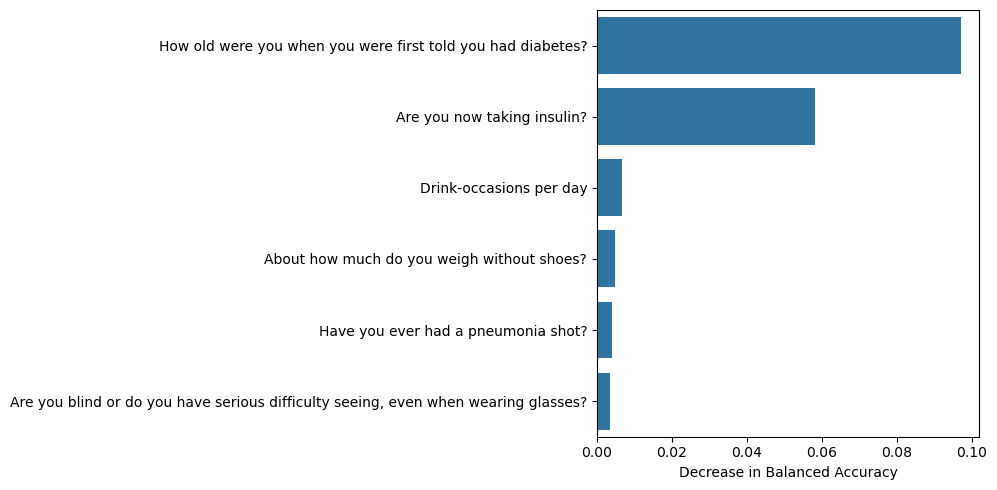

In [62]:
# Top 6 feature importance bar plot

plt.figure(figsize=(10, 5))

sns.barplot(
    data=imp_df.head(6),
    x="importance",
    y="feature_meaning",
    orient="h"
)

plt.xlabel("Decrease in Balanced Accuracy")
plt.ylabel("")
plt.tight_layout()
plt.show()

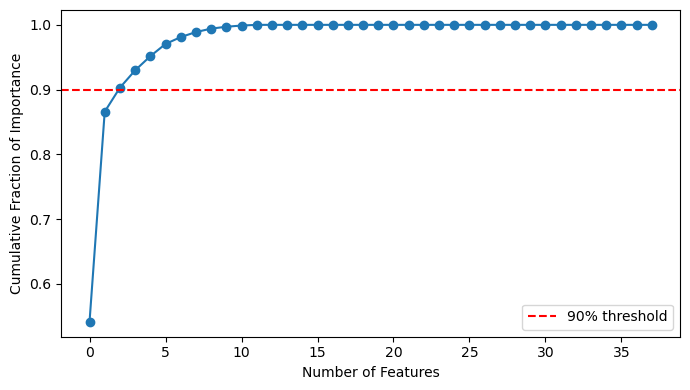

In [63]:
# Cumulative importance 
plt.figure(figsize=(7, 4))

plt.plot(imp_df["cum_frac"], marker="o")
plt.axhline(0.90, color="red", linestyle="--", label="90% threshold")

plt.xlabel("Number of Features")
plt.ylabel("Cumulative Fraction of Importance")
plt.legend()
plt.tight_layout()
plt.show()